# Task 1: Load Stock Price Data
Using the `yfinance` library to download historical stock price data for the analysis and modeling.

In [ ]:
!pip install yfinance

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Download historical data for a popular stock, e.g., Apple (AAPL)
ticker = 'AAPL'
df = yf.download(ticker, start='2020-01-01', end='2023-12-31')

# Display the first few rows of the data
display(df.head())

/tmp/ipykernel_2055/995729824.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start='2020-01-01', end='2023-12-31')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.271553,72.331709,71.029930,71.282583,135480400
2020-01-03,71.568932,72.326897,71.345153,71.501557,146322800
2020-01-06,72.139229,72.177730,70.442829,70.693080,118387200
2020-01-07,71.799911,72.403874,71.580942,72.148812,108872000
2020-01-08,72.954926,73.255706,71.503960,71.503960,132079200


# Task 2: Feature Engineering

Engineering features from the raw stock prices to help build the predictive models. This includes calculating Moving Averages, Daily Returns, and Volatility.

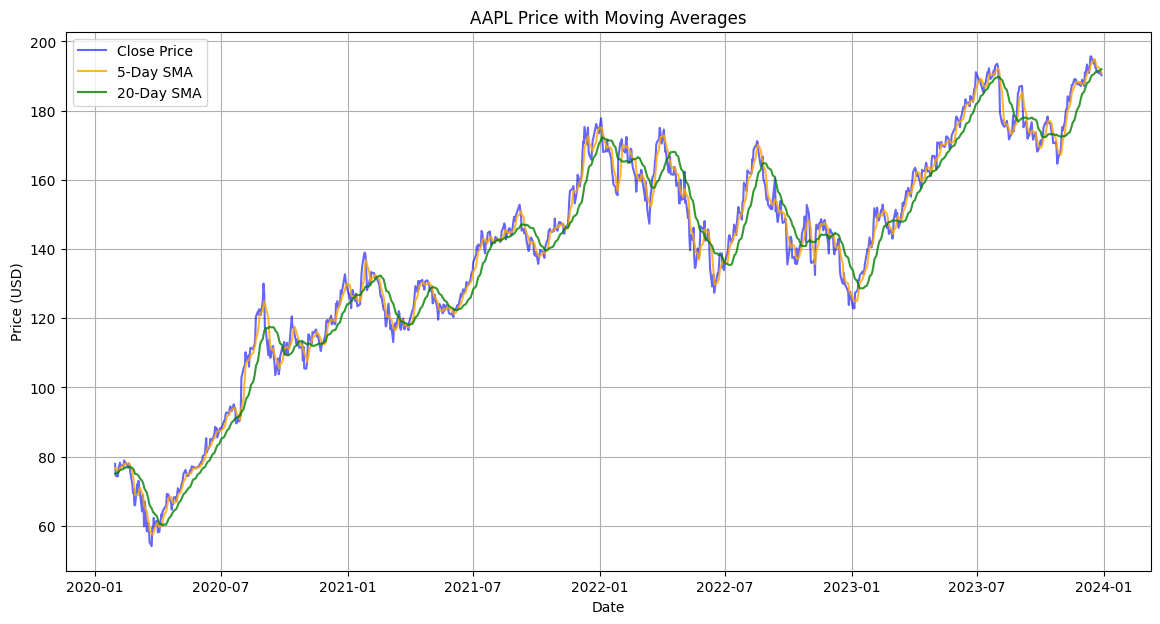

In [ ]:
# Create a clean copy to work with, flattening multi-index columns if necessary
df_features = df.copy()
if isinstance(df_features.columns, pd.MultiIndex):
    df_features.columns = df_features.columns.get_level_values(0)

# Calculate Features
df_features['SMA_5'] = df_features['Close'].rolling(window=5).mean()
df_features['SMA_20'] = df_features['Close'].rolling(window=20).mean()
df_features['Daily_Return'] = df_features['Close'].pct_change()
df_features['Volatility_5'] = df_features['Daily_Return'].rolling(window=5).std()

# Drop NaN values generated by moving windows
df_features.dropna(inplace=True)

# Visualize Close Price and Moving Averages
plt.figure(figsize=(14, 7))
plt.plot(df_features['Close'], label='Close Price', color='blue', alpha=0.6)
plt.plot(df_features['SMA_5'], label='5-Day SMA', color='orange', alpha=0.8)
plt.plot(df_features['SMA_20'], label='20-Day SMA', color='green', alpha=0.8)
plt.title(f'{ticker} Price with Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()

# Task 3: Model Building and Evaluation

Predicting the next day's Close price using our engineered features. Splitting the data chronologically to  a Linear Regression and a Random Forest Regressor, and evaluate both models.

=== Linear Regression Evaluation ===
Mean Squared Error (MSE): 4.3842
Root Mean Squared Error (RMSE): 2.0938
R2 Score: 0.9599

=== Random Forest Regressor Evaluation ===
Mean Squared Error (MSE): 93.3160
Root Mean Squared Error (RMSE): 9.6600
R2 Score: 0.1473



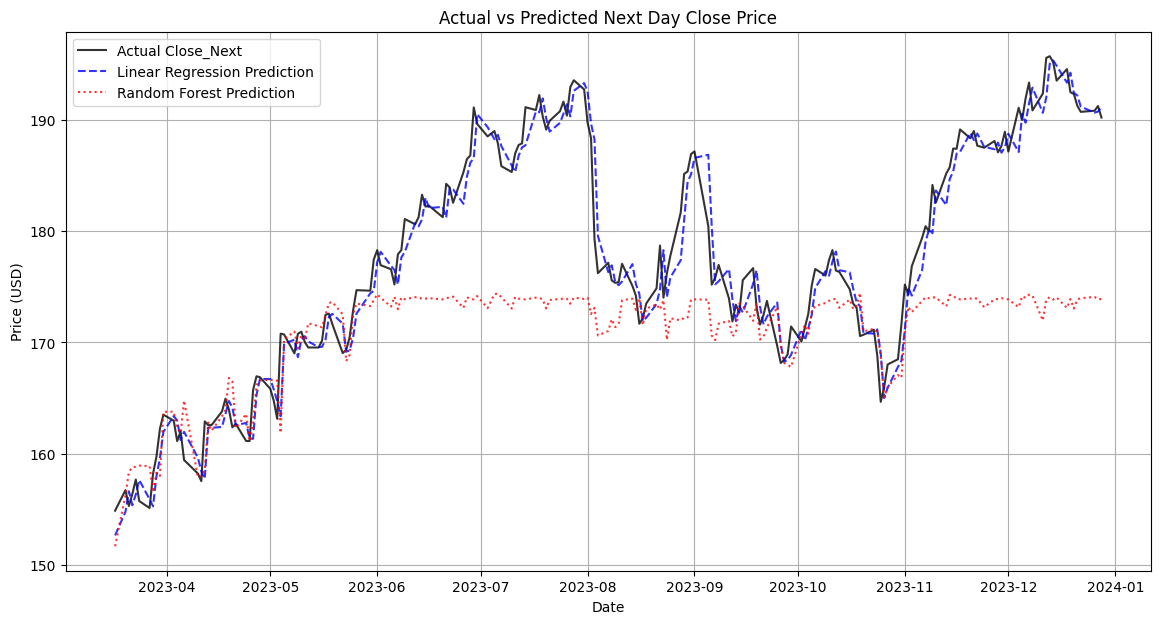

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Define target variable (Next day's Close price)
df_features['Close_Next'] = df_features['Close'].shift(-1)

# Drop the last row as it won't have a target value
df_model = df_features.dropna().copy()

# Define features (X) and target (y)
feature_cols = ['Close', 'SMA_5', 'SMA_20', 'Daily_Return', 'Volatility_5']
X = df_model[feature_cols]
y = df_model['Close_Next']

# 2. Chronological split (80% train, 20% test) to respect time series structure
split_index = int(len(df_model) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# 3. Model Training
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Predictions
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# 5. Evaluation Metrics
def evaluate(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"=== {model_name} Evaluation ===")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"R2 Score: {r2:.4f}\n")

evaluate(y_test, y_pred_lr, "Linear Regression")
evaluate(y_test, y_pred_rf, "Random Forest Regressor")

# Plot the actual vs predicted prices on test set
plt.figure(figsize=(14, 7))
plt.plot(y_test.index, y_test.values, label='Actual Close_Next', color='black', alpha=0.8)
plt.plot(y_test.index, y_pred_lr, label='Linear Regression Prediction', color='blue', linestyle='--', alpha=0.8)
plt.plot(y_test.index, y_pred_rf, label='Random Forest Prediction', color='red', linestyle=':', alpha=0.8)
plt.title('Actual vs Predicted Next Day Close Price')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()

# Task 4: Trading Strategies & Backtesting

Building a simple strategy using our top-performing model (Linear Regression) to decide whether to hold the stock or stay in cash day-by-day. Then, evaluate and compare the cumulative returns against a simple Buy-and-Hold strategy.

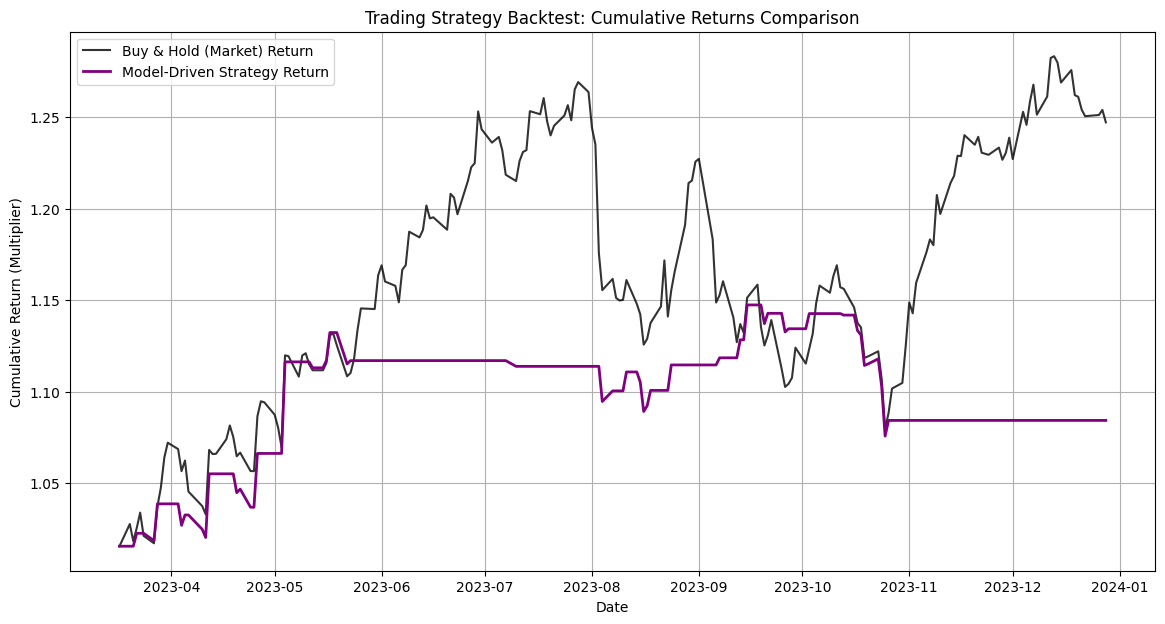

Final Buy & Hold Cumulative Return: 24.72%
Final Model Strategy Cumulative Return: 8.43%


In [ ]:
# Create a DataFrame for backtesting on the testing set
backtest_df = pd.DataFrame(index=X_test.index)
backtest_df['Actual_Close'] = X_test['Close']
backtest_df['Predicted_Next'] = y_pred_lr

# Shift actual Close price to represent tomorrow's actual Close for return calculation
backtest_df['Actual_Next'] = y_test

# Calculate market returns (Daily Return of holding the stock)
backtest_df['Market_Daily_Return'] = (backtest_df['Actual_Next'] - backtest_df['Actual_Close']) / backtest_df['Actual_Close']

# Generate signal: 1 (Buy/Hold) if predicted price goes up, 0 (Cash) if predicted price goes down
backtest_df['Signal'] = np.where(backtest_df['Predicted_Next'] > backtest_df['Actual_Close'], 1, 0)

# Strategy daily return: If signal is 1, we get market return. If 0, we get 0% (Cash)
backtest_df['Strategy_Daily_Return'] = backtest_df['Signal'] * backtest_df['Market_Daily_Return']

# Calculate Cumulative Returns
backtest_df['Cumulative_Market_Return'] = (1 + backtest_df['Market_Daily_Return']).cumprod()
backtest_df['Cumulative_Strategy_Return'] = (1 + backtest_df['Strategy_Daily_Return']).cumprod()

# Plot the results
plt.figure(figsize=(14, 7))
plt.plot(backtest_df['Cumulative_Market_Return'], label='Buy & Hold (Market) Return', color='black', alpha=0.8)
plt.plot(backtest_df['Cumulative_Strategy_Return'], label='Model-Driven Strategy Return', color='purple', linewidth=2)
plt.title('Trading Strategy Backtest: Cumulative Returns Comparison')
plt.xlabel('Date')
plt.ylabel('Cumulative Return (Multiplier)')
plt.legend()
plt.grid(True)
plt.show()

# Print final performance
final_market = backtest_df['Cumulative_Market_Return'].iloc[-1]
final_strat = backtest_df['Cumulative_Strategy_Return'].iloc[-1]
print(f"Final Buy & Hold Cumulative Return: {(final_market - 1)*100:.2f}%")
print(f"Final Model Strategy Cumulative Return: {(final_strat - 1)*100:.2f}%")